# Direct Dynamics in Curvilinear Coordinates

In the previous tutorials, the dynamics is propagated in the redundant Cartesian coordinates with constraints, and the curvilinear coordinates are used only in the analysis.

This tutorial introduces an alternative way to propagate the dynamics directly in curvilinear coordinates $Q$ with the Hamiltonian:

\begin{align*}
H(Q, P) = \frac{1}{2} P^T G(Q) P + V(Q),
\end{align*}

where $G(Q)$ is the (inverse) metric of the kinetic energy.

- Since the kinetic energy depends on $Q$, this Hamiltonian is not separable and cannot be propagated by SHAKE/RATTLE. Instead, the implicit Verlet integrator [`ImplicitVerlet`](https://tsumura-m.github.io/PySCIVR/pyscivr.integrators.html#pyscivr.integrators.ImplicitVerlet) is used (Appendix J of the paper), which solves two implicit equations by Newton's method in each step.

- Since the dynamics does not go through the redundant space, it is vulnerable to the coordinate singularities. This is demonstrated by the rotation of H2.

- Nevertheless, when the coordinates are known to have no singularities, the direct dynamics can be advantageous in accuracy and computational cost. A typical example is the pure rotation of a nonlinear molecule by the quaternion, demonstrated by CH4.

In [ ]:
# import necessary libraries

import time
 
import numpy as np
import matplotlib.pyplot as plt
import jax.numpy as jnp
 
from pyscivr.coordinates import InternalCoordinates, QuaternionCoordinates, quaternion_metric
from pyscivr.integrators import ImplicitVerlet, ShakeRattle
from pyscivr.potentials import ZeroPotential
from pyscivr.units import CmInv, FemtoSec
from pyscivr.utils import get_geom, get_inertia, get_mass_center
from pyscivr.variations import (make_jacobi_func, make_vari_propagator, make_vari_propagator_implicit,
                                propagate_variation, propagate_variation_implicit, to_internal)

## Pure rotation of hydrogen

The Hamiltonian of the rigid rotation of H2 in the polar and azimuthal angles is

\begin{align*}
H(\theta, \phi, p_\theta, p_\phi) = \frac{1}{2I} \left( p_\theta^2 + \frac{p_\phi^2}{\sin^2\theta} \right), \nonumber
\end{align*}

so that the metric is

\begin{align*}
G(\theta, \phi) = \frac{1}{I} \begin{pmatrix} 1 & 0 \\ 0 & \frac{1}{\sin^2\theta} \end{pmatrix}. \nonumber
\end{align*}

`ImplicitVerlet` takes the metric $G(Q)$ as a function. A potential $V(Q)$ can also be given by `potential_func` (zero by default); note that it must be a function of the curvilinear coordinates $Q$, written with `jax.numpy` so that it can be differentiated automatically.

In [2]:
xyzstr = """
H        -0.370801958573       0.000000000000       0.000000000000
H         0.370801958573       0.000000000000       0.000000000000
"""
symbols, posi_ref, mass = get_geom(xyzstr)

r_e = np.linalg.norm(posi_ref[1] - posi_ref[0])
inertia_h2 = 0.5 * mass[0] * r_e**2

coord_const_h2 = InternalCoordinates(posi_ref, mass)
coord_const_h2.add_translation()
coord_const_h2.add_bond(0, 1)
coord_const_h2.build()
 
coord_all_h2 = InternalCoordinates(posi_ref, mass)
coord_all_h2.add_translation()
coord_all_h2.add_polar(0, 1)
coord_all_h2.add_azimuthal(0, 1)
coord_all_h2.add_bond(0, 1)
coord_all_h2.build()
idx_polar = coord_all_h2.find_coordinate("polar", (0, 1))[0]

def metric_h2(posi): # [theta, phi]
    """Metric for the polar and azimuthal angles, posi = (theta, phi)."""
    theta = posi[0]
    return jnp.diag(jnp.array([1.0, 1.0 / jnp.sin(theta)**2])) / inertia_h2

def analytical(t, L, tilt):
    """Exact (theta, phi) of the free rotor starting along the x-axis, rotating in the plane tilted by `tilt`."""
    omega = L / inertia_h2
    n = np.cos(omega * t)[:, None] * np.array([1.0, 0.0, 0.0]) \
        + np.sin(omega * t)[:, None] * np.array([0.0, np.cos(tilt), np.sin(tilt)])
    return np.arccos(np.clip(n[:, 2], -1, 1)), np.arctan2(n[:, 1], n[:, 0])

Build complete: 4 coordinates
Build complete: 6 coordinates


The same rotation is propagated in two ways:

- **Implicit**: directly in $(\theta, \phi)$ by `ImplicitVerlet`, with $p_\theta (t=0) = L \sin(\text{tilt})$ and $p_\phi (t=0) = L \cos(\text{tilt})$, where $L$ is the total angular momentum.

- **SHAKE/RATTLE**: in the redundant Cartesian coordinates with the constraints on the bond length and the center of mass, as in the Constrained Dynamics tutorial.

In [3]:
def wrap_phi(phi):
    """Wrap azimuthal angle to [-pi, pi]."""
    return (phi + np.pi) % (2 * np.pi) - np.pi

def compare_h2(tilt, K_rot=1000.0, dt_fs=0.1, n_step=10000):
    dt = dt_fs * FemtoSec
    p_rot = np.sqrt(K_rot * CmInv * mass[0])  # momentum of each atom
    L = r_e * p_rot # total angular momentum
    t = dt * np.arange(n_step + 1)
 
    # Implicit Verlet
    traj_imp = ImplicitVerlet(np.array([np.pi / 2, 0.0]), np.array([-L * np.sin(tilt), L * np.cos(tilt)]),
                              dt, metric_h2).run(n_step)
 
    # SHAKE/RATTLE
    mome_shake = np.array([[0.0, -p_rot * np.cos(tilt), -p_rot * np.sin(tilt)],
                          [0.0, p_rot * np.cos(tilt), p_rot * np.sin(tilt)]])
    traj_shake = ShakeRattle(ZeroPotential(), posi_ref, mome_shake, mass, dt, coord_const_h2).run(n_step)
    values = np.asarray(coord_all_h2.get_value_batch(traj_shake["posi"].reshape(n_step + 1, -1)))
 
    theta_ex, phi_ex = analytical(t, L, tilt)
    phi_ex = wrap_phi(phi_ex)
    theta_imp, phi_imp = traj_imp["posi"][:, 0], traj_imp["posi"][:, 1]
    phi_imp = wrap_phi(phi_imp)
    theta_shake, phi_shake = values[:, idx_polar], values[:, idx_polar + 1]
    phi_shake = wrap_phi(phi_shake)

    energy_imp = traj_imp["total_energy"]
    energy_shake = traj_shake["total_energy"]

    fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)

    ax[0].plot(t / FemtoSec, np.degrees(theta_ex), color="black", label="exact")
    ax[0].plot(t / FemtoSec, np.degrees(theta_imp), "--", label="implicit")
    ax[0].plot(t / FemtoSec, np.degrees(theta_shake), ":", label="SHAKE/RATTLE")
    ax[0].set_title(f"tilt = {np.degrees(tilt):.1f} deg")
    ax[0].set_ylabel(r"$\theta$ (deg)")
    ax[0].legend()

    ax[1].plot(t / FemtoSec, np.degrees(phi_ex), color="black", label="exact")
    ax[1].plot(t / FemtoSec, np.degrees(phi_imp), "--", label="implicit")
    ax[1].plot(t / FemtoSec, np.degrees(phi_shake), ":", label="SHAKE/RATTLE")
    ax[1].set_xlabel("Time (fs)")
    ax[1].set_ylabel(r"$\phi$ (deg)")
    ax[1].legend()

    ax[2].hlines(K_rot, t[0] / FemtoSec, t[-1] / FemtoSec, color="black", label="exact")
    ax[2].plot(t / FemtoSec, energy_imp / CmInv, "--", label="implicit")
    ax[2].plot(t / FemtoSec, energy_shake / CmInv, ":", label="SHAKE/RATTLE")
    ax[2].set_xlabel("Time (fs)")
    ax[2].set_ylabel("Total energy (cm$^{-1}$)")
    ax[2].legend()
    plt.show()

For a trajectory far from the poles, both methods agree with the exact solution.

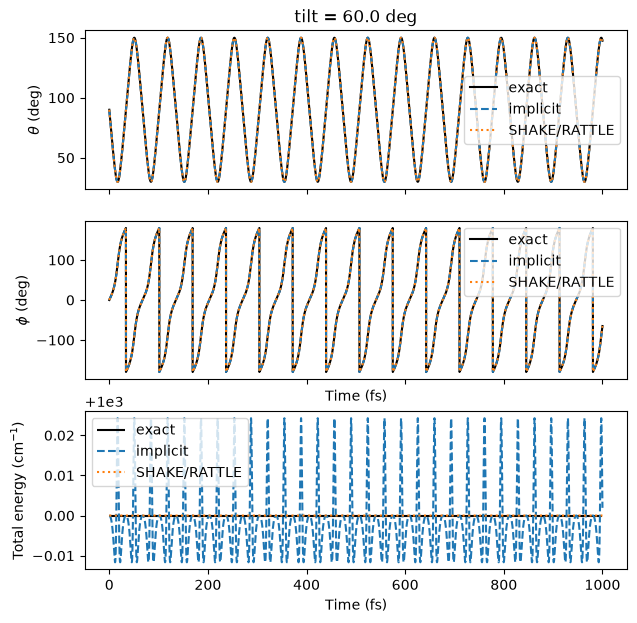

In [4]:
compare_h2(tilt=np.radians(60.0))

When the trajectory passes close to the poles ($\theta = 0, \pi$), the implicit integration breaks down.

Near the poles, the term $\frac{1}{\sin^2\theta}$ in the metric diveges and makes the dynamics instable.

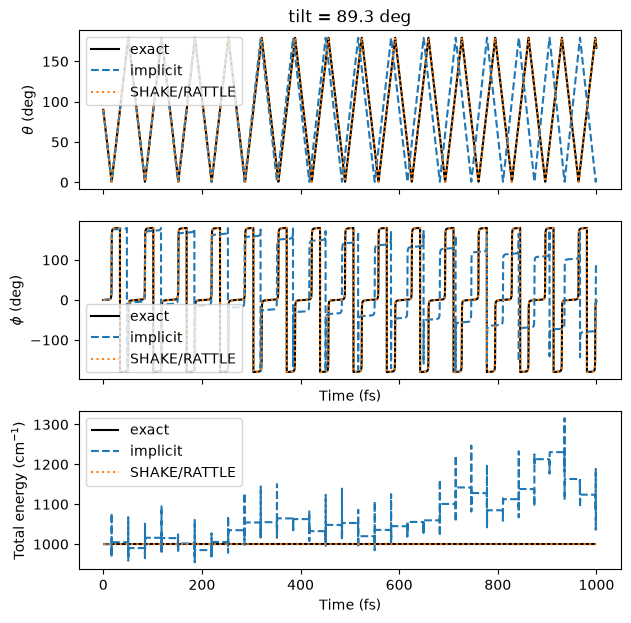

In [5]:
compare_h2(tilt=np.radians(89.3))

## Pure rotation of methane by the quaternion

The pure rotation of H2 was treated by SHAKE/RATTLE with the constraint on the bond length.

For a nonlinear molecule, the pure rotation can be treated in the same way by constraining all the $3N - 6$ vibrational coordinates, but this is clearly inefficient: for CH4, 15 Cartesian coordinates are propagated with 12 constraints to describe only 3 rotational DOFs.
Instead, the rotation can be described by the quaternion $q$ (4 components) without singularities.

Since the physical DOFs of the rotation are three, the quaternion is a redundant coordinate with one constraint $q^T q = 1$. The physical coordinates are the Euler angles (yaw $\psi$, pitch $\theta$ and roll $\phi$), which have singularities known as the gimbal lock.

In PySCIVR, the pitch angle is shifted by $\pi / 2$ from the usual domain $[-\pi / 2, \pi / 2]$ of the ZYX convention to $[0, \pi]$, so that the gimbal lock occurs at $\theta = 0, \pi$.

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Quaternion (4 DOFs) with 1 constraint (norm) | none | `ImplicitVerlet` | Euler angles (3 DOFs) |

Note that both the quaternion and the Euler angles are curvilinear coordinates:
the redundant space is not limited to the Cartesian coordinates.

- The norm constraint is simple, so it is handled inside `ImplicitVerlet` with `normalize=True`.

- The metric is given by `quaternion_metric` with the principal moments of inertia.

- The transformation between the quaternion and the Euler angles is given by [`QuaternionCoordinates`](https://tsumura-m.github.io/PySCIVR/pyscivr.coordinates.html#pyscivr.coordinates.QuaternionCoordinates) instead of `InternalCoordinates`.

- The variation is propagated by `make_vari_propagator_implicit` and `propagate_variation_implicit`.

The result is compared with SHAKE/RATTLE in the Cartesian coordinates with all the $3N - 6 = 9$ vibrational coordinates and the center of mass constrained.

In [ ]:
xyzstr = """
C        -0.000000000000       0.000000000000      -0.000000000000
H         0.627615334142       0.627615334142       0.627615334142
H        -0.627615334142      -0.627615334142       0.627615334142
H         0.627615334142      -0.627615334142      -0.627615334142
H        -0.627615334142       0.627615334142      -0.627615334142
"""
symbols, posi_ref, mass = get_geom(xyzstr)
assert np.allclose(get_mass_center(posi_ref, mass), 0.0)
inertia_tensor = get_inertia(posi_ref, mass)
assert np.allclose(inertia_tensor, np.diag(np.diag(inertia_tensor))) # principal axis frame
inertia = np.diag(inertia_tensor)
 
dt = 0.1 * FemtoSec
n_step = 10000
 
# initial angular momentum in the body frame
K_rot = 2000.0 * CmInv
L_dir = np.array([2.0, -1.0, 2.0])
L_body = np.sqrt(2.0 * K_rot / np.sum(L_dir**2 / inertia)) * L_dir # K_rot = L^T I^{-1} L / 2
omega = L_body / inertia
 
 
def get_S(q):
    """omega_body = 2 S(q) dq/dt, p = 2 S(q)^T L_body (|q| = 1)."""
    q0, q1, q2, q3 = q
    return np.array([[-q1, q0, q3, -q2],
                     [-q2, -q3, q0, q1],
                     [-q3, q2, -q1, q0]])

### (A) Implicit integration with the quaternion

In [7]:
posi_quat = np.array([1.0, 0.0, 0.0, 0.0])
mome_quat = 2.0 * L_body @ get_S(posi_quat)
metric_func = quaternion_metric(inertia)

coord_quat = QuaternionCoordinates()
active_quat = np.array([0, 1, 2]) # yaw, pitch, roll (the norm is the constraint)
_, jacobi_rev_quat, _, monodromy_quat = make_jacobi_func(coord_quat, active_quat)
vari_propagator_implicit = make_vari_propagator_implicit(metric_func, dt, normalize=True)

for trial in range(3): # the first trial includes the JIT compilation
    t0 = time.perf_counter()
    traj_quat = ImplicitVerlet(posi_quat, mome_quat, dt, metric_func, normalize=True).run(n_step)
    vari_quat = propagate_variation_implicit(vari_propagator_implicit,
                                             traj_quat["posi"], traj_quat["mome"], traj_quat["mome_half"],
                                             jacobi_rev_quat(traj_quat["posi"][0], traj_quat["mome"][0]))
    euler_quat, _, mono_quat, symp_err_quat = to_internal(monodromy_quat, traj_quat["posi"], traj_quat["mome"], vari_quat)
    print(f"implicit (trial {trial}): {time.perf_counter() - t0:.1f} sec")

implicit (trial 0): 1.1 sec
implicit (trial 1): 0.2 sec
implicit (trial 2): 0.1 sec


### (B) SHAKE/RATTLE with all the vibrational coordinates constrained

In [8]:
bonds = [(0, i) for i in range(1, 5)]
angles = [(0, 1, i) for i in range(2, 5)]
dihedrals = [(0, 1, 2, i) for i in range(3, 5)]

coord_const = InternalCoordinates(posi_ref, mass)
coord_const.add_translation()
coord_all = InternalCoordinates(posi_ref, mass)
coord_all.add_translation()
coord_all.add_euler()
for c in (coord_const, coord_all):
    for idx in bonds:
        c.add_bond(*idx)
    for idx in angles:
        c.add_angle(*idx)
    for idx in dihedrals:
        c.add_dihedral(*idx)
    c.build()

active_cart = np.array([coord_all.index[name] for name in ("euler_yaw", "euler_pitch", "euler_roll")])
_, jacobi_rev_cart, _, monodromy_cart = make_jacobi_func(coord_all, active_cart)

mome_cart = mass[:, None] * np.cross(omega, posi_ref) # p_a = m_a omega x r_a
vari_propagator = make_vari_propagator(coord_const, dt)

for trial in range(3): # the first trial includes the JIT compilation
    t0 = time.perf_counter()
    traj_cart = ShakeRattle(ZeroPotential(), posi_ref, mome_cart, mass, dt, coord_const).run(n_step)
    vari_cart = propagate_variation(vari_propagator, traj_cart["posi"], traj_cart["mome"],
                                    traj_cart["lam"], traj_cart["mu"], np.zeros((n_step + 1, 15, 15)),
                                    jacobi_rev_cart(traj_cart["posi"][0], traj_cart["mome"][0]))
    euler_cart, _, mono_cart, symp_err_cart = to_internal(monodromy_cart, traj_cart["posi"], traj_cart["mome"], vari_cart)
    print(f"SHAKE/RATTLE (trial {trial}): {time.perf_counter() - t0:.1f} sec")

Build complete: 12 coordinates
Build complete: 15 coordinates
SHAKE/RATTLE (trial 0): 4.9 sec
SHAKE/RATTLE (trial 1): 2.1 sec
SHAKE/RATTLE (trial 2): 2.1 sec


### Comparison

77 of 10001 steps are excluded.
max |Euler (implicit) - Euler (SHAKE/RATTLE)| = 1.05e-04
max relative difference of M                  = 4.10e-03


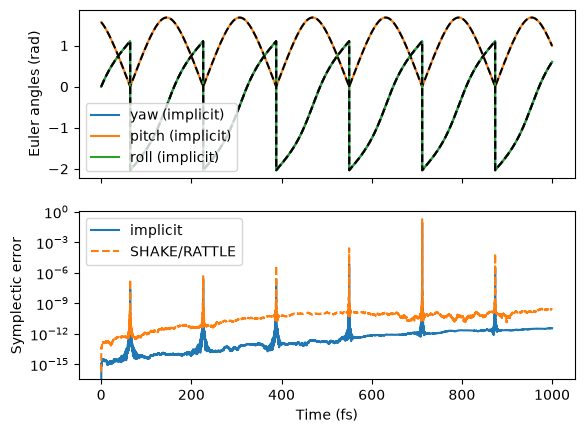

In [9]:
valid = (symp_err_cart < 1e-9) # exclude the vicinity of singularities
print(f"{np.sum(~valid)} of {len(valid)} steps are excluded.")

d_euler = (euler_quat - euler_cart + np.pi) % (2 * np.pi) - np.pi
rel_err = np.max(np.abs(mono_quat - mono_cart), axis=(1, 2)) / np.max(np.abs(mono_cart), axis=(1, 2))
print(f"max |Euler (implicit) - Euler (SHAKE/RATTLE)| = {np.max(np.abs(d_euler[valid])):.2e}")
print(f"max relative difference of M                  = {np.max(rel_err[valid]):.2e}")

t_fs = dt / FemtoSec * np.arange(n_step + 1)
fig, axes = plt.subplots(2, 1, sharex=True)
for k, name in enumerate(("yaw", "pitch", "roll")):
    axes[0].plot(t_fs, euler_quat[:, k], label=f"{name} (implicit)")
    axes[0].plot(t_fs, euler_cart[:, k], "--", color="black")
axes[0].set_ylabel("Euler angles (rad)")
axes[0].legend()
axes[1].semilogy(t_fs, symp_err_quat, label="implicit")
axes[1].semilogy(t_fs, symp_err_cart, "--", label="SHAKE/RATTLE")
axes[1].set_ylabel("Symplectic error")
axes[1].set_xlabel("Time (fs)")
axes[1].legend()
plt.show()

- **Efficiency**: Excluding the JIT compilation (i.e., from the second run), the implicit integration with the quaternion takes 0.2 s, about ten times faster than SHAKE/RATTLE with all the vibrational coordinates constrained (2.1 s). Only 4 coordinates are propagated instead of 15 Cartesian coordinates with 12 constraints, and the whole propagation is compiled into a single function. Note that this comparison is for the pure rotation, where no potential evaluation is needed; with ab initio potentials, the cost is dominated by the force evaluations.

- **Accuracy**: The symplectic error of the implicit integration (about $10^{-13}$) is smaller than that of SHAKE/RATTLE (about $10^{-10}$) along the whole trajectory.

- **Agreement**: Excluding the 77 of 10001 steps in the vicinity of the gimbal lock, the two methods give the same Euler angles (within $10^{-4}$ rad) and monodromy matrices (relative difference within $4 \times 10^{-3}$).

- **Singularities**: Near the gimbal lock, the symplectic error actually increases for both methods (up to about $10^{-1}$ for SHAKE/RATTLE), since the transformation to the Euler angles diverges. 
  As discussed in the Hessian and Variation tutorial, such steps must be detected by the symplectic error and excluded from the spectrum calculation.